# 10 — Trade-off Efisiensi vs Akurasi

"Arsitektur terbaik" bergantung pada tempat pemakaiannya. Notebook ini mengumpulkan angka yang dibutuhkan untuk argumen itu: jumlah parameter, ukuran model, waktu inferensi, throughput, dan estimasi FLOPs — lalu menurunkan rekomendasi per skenario deployment.

> **Pengukuran waktu bergantung perangkat.** Angka di sini berlaku untuk GPU mesin ini, dengan batch 1. Model yang parameternya jauh lebih sedikit belum tentu lebih cepat di GPU: depthwise convolution pada MobileNetV3 bersifat memory-bound dan kurang memanfaatkan paralelisme GPU. Sebutkan ini di laporan alih-alih menyimpulkan "lebih kecil = lebih cepat".

## Setup

In [1]:
# Bootstrap: tambahkan root proyek ke sys.path agar modul src/ & configs/ dapat diimpor.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('PROJECT_ROOT:', PROJECT_ROOT)

PROJECT_ROOT: c:\Users\DZXP\Documents\ta-green-bean


In [2]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from configs.base_config import ANALYSIS_DIR, DEVICE, FIGURES_DIR, METRICS_DIR, MODELS_DIR, NUM_CLASSES
from configs.cnn_config import CNN_CONFIG
from src.analysis.efficiency_analysis import (
    efficiency_table,
    measure_model_efficiency,
    plot_efficiency_accuracy_tradeoff,
    plot_inference_time_comparison,
    plot_size_vs_metric,
)
from src.analysis.style import apply_plot_style
from src.models.model_factory import get_model
from src.utils.io import load_checkpoint

apply_plot_style()
print('device pengukuran:', DEVICE)

device pengukuran: cuda


## 1. Ukur efisiensi tiap arsitektur

In [3]:
N_RUNS = 100

efficiency = {}
for name, config in CNN_CONFIG.items():
    folder = MODELS_DIR / name
    checkpoints = sorted(folder.glob('*.pt')) if folder.is_dir() else []

    model = get_model(name, num_classes=NUM_CLASSES, pretrained=False)
    if checkpoints:
        load_checkpoint(model, checkpoints[-1], map_location=DEVICE)

    input_size = int(config['input_size'])
    efficiency[name] = measure_model_efficiency(
        model,
        input_shape=(1, 3, input_size, input_size),
        device=DEVICE,
        n_runs=N_RUNS,
        checkpoint_path=checkpoints[-1] if checkpoints else None,
    )
    print(f"{name:<14} {efficiency[name]['params_total']:>12,} params  "
          f"{efficiency[name]['inference_time_ms']:>7.2f} ms  "
          f"{efficiency[name]['flops'] / 1e9:>6.2f} GMAC")

resnet50         23,518,277 params     6.65 ms    4.09 GMAC
mobilenetv3       4,208,437 params     5.32 ms    0.22 GMAC
inceptionv3      21,795,813 params    10.87 ms    5.71 GMAC


## 2. Gabungkan dengan metrik akurasi

In [4]:
for name in efficiency:
    path = METRICS_DIR / f'{name}_test_metrics.json'
    if path.exists():
        report = json.loads(path.read_text(encoding='utf-8'))
        efficiency[name]['accuracy'] = report.get('accuracy')
        efficiency[name]['f1'] = report.get('f1')
        efficiency[name]['defect_recall'] = report.get('defect_recall')
    else:
        print(f'{name}: metrik belum ada, kolom akurasi dibiarkan kosong')

df_eff = efficiency_table(efficiency)
df_eff.to_csv(ANALYSIS_DIR / 'efficiency_comparison.csv', encoding='utf-8')
df_eff

,params_total,params_trainable,model_size_mb,inference_time_ms,throughput_img_per_s,flops,input_size,device,checkpoint_size_mb,accuracy,f1,defect_recall
model,,,,,,,,,,,,
resnet50,23518277,10245,89.715,6.6453,150.48,4087146496,224,cuda,90.025,0.79606,0.736286,0.876168
mobilenetv3,4208437,6405,16.054,5.3231,187.86,215316160,224,cuda,16.257,0.762457,0.700104,0.815421
inceptionv3,21795813,10245,83.144,10.8687,92.01,5711178336,299,cuda,83.477,0.755504,0.67408,0.801402


## 3. Tabel ringkas untuk laporan

In [5]:
cols = [c for c in ['f1', 'accuracy', 'defect_recall', 'params_total',
                    'params_trainable', 'model_size_mb', 'inference_time_ms',
                    'throughput_img_per_s', 'flops', 'input_size'] if c in df_eff.columns]
table = df_eff[cols].copy()
if 'flops' in table.columns:
    table['GMAC'] = (table['flops'] / 1e9).round(2)
    table = table.drop(columns='flops')
table

,f1,accuracy,defect_recall,params_total,params_trainable,model_size_mb,inference_time_ms,throughput_img_per_s,input_size,GMAC
model,,,,,,,,,,
resnet50,0.736286,0.79606,0.876168,23518277,10245,89.715,6.6453,150.48,224,4.09
mobilenetv3,0.700104,0.762457,0.815421,4208437,6405,16.054,5.3231,187.86,224,0.22
inceptionv3,0.67408,0.755504,0.801402,21795813,10245,83.144,10.8687,92.01,299,5.71


## 4. Scatter plot trade-off

Sumbu x = parameter (log), sumbu y = F1, ukuran titik = waktu inferensi. Arsitektur yang ideal berada di kiri-atas dengan titik kecil.

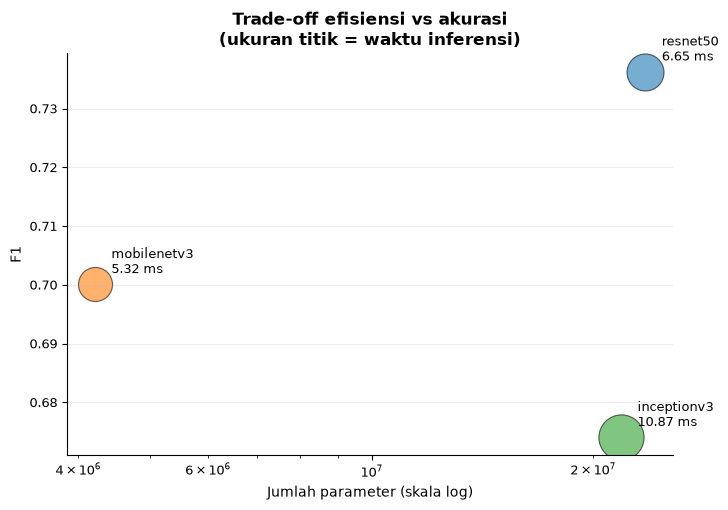

In [6]:
if df_eff['f1'].notna().any():
    plot_efficiency_accuracy_tradeoff(
        efficiency, metric='f1',
        output_path=FIGURES_DIR / 'efficiency_accuracy_tradeoff.png',
    )
    plt.show()
else:
    print('Belum ada metrik F1; jalankan scripts.evaluate dulu.')

## 5. Perbandingan waktu inferensi & ukuran model

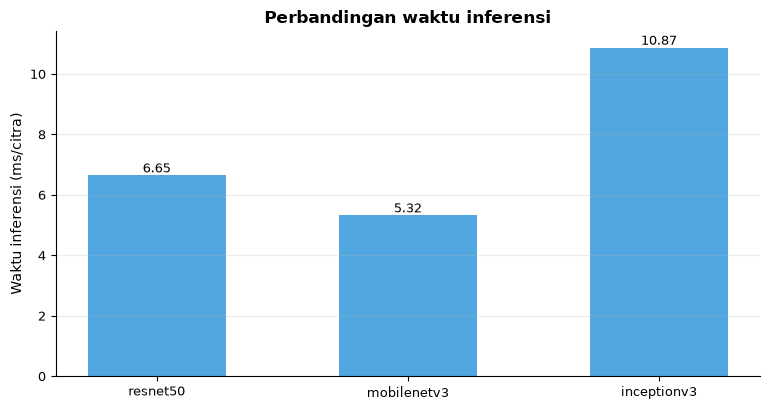

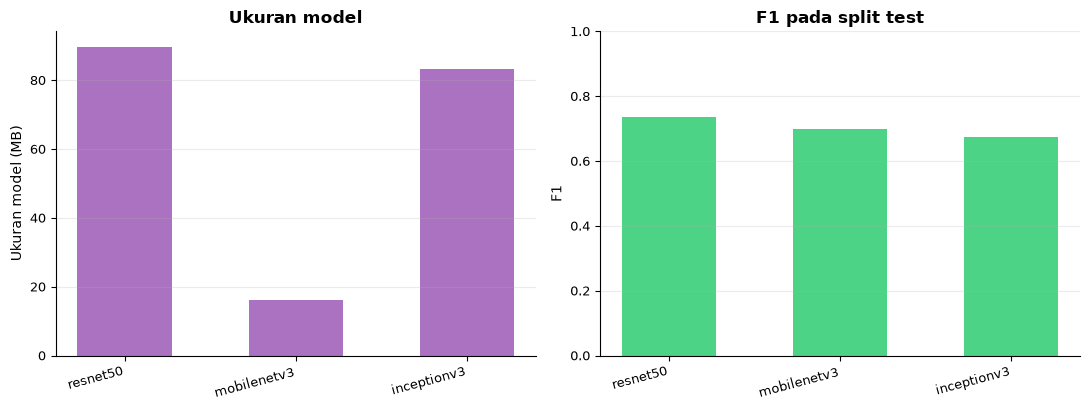

In [7]:
plot_inference_time_comparison(
    efficiency, output_path=FIGURES_DIR / 'inference_time_comparison.png'
)
plt.show()

if df_eff['f1'].notna().any():
    plot_size_vs_metric(efficiency, metric='f1', output_path=FIGURES_DIR / 'size_vs_f1.png')
    plt.show()

## 6. Efisiensi relatif

Dinormalkan terhadap model terkecil, supaya "berapa kali lebih besar/lambat" terbaca langsung.

In [8]:
relative = pd.DataFrame(index=df_eff.index)
relative['params_x'] = (df_eff['params_total'] / df_eff['params_total'].min()).round(2)
relative['size_x'] = (df_eff['model_size_mb'] / df_eff['model_size_mb'].min()).round(2)
relative['latency_x'] = (df_eff['inference_time_ms'] / df_eff['inference_time_ms'].min()).round(2)
relative['flops_x'] = (df_eff['flops'] / df_eff['flops'].min()).round(2)
if df_eff['f1'].notna().any():
    relative['f1_delta'] = (df_eff['f1'] - df_eff['f1'].max()).round(4)
relative

,params_x,size_x,latency_x,flops_x,f1_delta
model,,,,,
resnet50,5.59,5.59,1.25,18.98,0.0
mobilenetv3,1.0,1.0,1.0,1.0,-0.0362
inceptionv3,5.18,5.18,2.04,26.52,-0.0622


## 7. Rekomendasi per skenario deployment

Diturunkan dari angka di atas, bukan dari preferensi arsitektur.

In [9]:
if df_eff['f1'].notna().any():
    best_f1 = df_eff['f1'].idxmax()
    smallest = df_eff['params_total'].idxmin()
    fastest = df_eff['inference_time_ms'].idxmin()
    best_qc = df_eff['defect_recall'].idxmax() if df_eff.get('defect_recall') is not None and df_eff['defect_recall'].notna().any() else None

    print('F1 macro tertinggi      :', best_f1, f"({df_eff.loc[best_f1, 'f1']:.4f})")
    print('Parameter paling sedikit:', smallest, f"({df_eff.loc[smallest, 'params_total']:,})")
    print('Inferensi tercepat      :', fastest, f"({df_eff.loc[fastest, 'inference_time_ms']:.2f} ms)")
    if best_qc:
        print('Recall cacat tertinggi  :', best_qc, f"({df_eff.loc[best_qc, 'defect_recall']:.4f})")
    print()

    gap = df_eff.loc[best_f1, 'f1'] - df_eff.loc[smallest, 'f1']
    print('--- Rekomendasi ---')
    print(f'Server / akurasi diutamakan : {best_f1}')
    if smallest == best_f1:
        print(f'Perangkat tepi              : {smallest} (sekaligus paling akurat)')
    elif gap < 0.02:
        print(f'Perangkat tepi              : {smallest} '
              f'(hanya {gap:.4f} F1 di bawah {best_f1}, '
              f"{relative.loc[best_f1, 'params_x'] / relative.loc[smallest, 'params_x']:.1f}x lebih kecil)")
    else:
        print(f'Perangkat tepi              : {smallest}, tetapi F1-nya {gap:.4f} '
              f'di bawah {best_f1} — pertimbangkan apakah selisih itu dapat diterima')
else:
    print('Belum ada metrik akurasi; rekomendasi tidak dapat disusun.')

F1 macro tertinggi      : resnet50 (0.7363)
Parameter paling sedikit: mobilenetv3 (4,208,437)
Inferensi tercepat      : mobilenetv3 (5.32 ms)
Recall cacat tertinggi  : resnet50 (0.8762)

--- Rekomendasi ---
Server / akurasi diutamakan : resnet50
Perangkat tepi              : mobilenetv3, tetapi F1-nya 0.0362 di bawah resnet50 — pertimbangkan apakah selisih itu dapat diterima


## 8. Catatan untuk laporan

- Sebutkan perangkat dan batch size pengukuran (`DEVICE`, batch 1). Tanpa itu,   angka latensi tidak bisa ditafsirkan.
- `flops` di sini adalah estimasi **MAC** untuk Conv2d dan Linear saja   (BatchNorm, aktivasi, dan pooling diabaikan). Cocok untuk membandingkan   arsitektur, tidak untuk diklaim sebagai hitungan FLOP eksak.
- `params_trainable` hanya mencakup head klasifikasi, karena skemanya feature   extraction. Biaya pelatihan jauh lebih kecil daripada yang disiratkan   `params_total`.
- InceptionV3 memproses input 299x299 (bukan 224), jadi FLOPs dan latensinya   lebih tinggi sebagian karena ukuran inputnya, bukan semata arsitekturnya.